# Feature Engineering + Feature Selection + Model Comparison (India Hospital Readmission)
Standalone: needs only pandas / numpy / scikit-learn / matplotlib (+ kagglehub for the download). No GPU needed.
**Compares three feature sets** (baseline -> engineered -> engineered+selected) x **three models** (Logistic Regression, HistGradientBoosting, Random Forest).
**Leakage controls:** temporal split (train 2015-21 / val 2022 / test 2023-24); target encodings use only past admissions whose 30-day label was already known;
feature selection and thresholds use validation data only; `Expired` discharges and `readmitted_7d` dropped. The label is provided in the data, so no synthetic dates are needed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
CFG = dict(DATA_DIR=None, OUT_DIR='fe_outputs', TRAIN_END_YEAR=2021, VAL_YEAR=2022, SEED=42,
           TE_SMOOTH=20, LR_C_GRID=[0.01, 0.1, 1.0], RF_TREES=300, RF_MIN_LEAF=30, PERM_REPEATS=5, N_BOOT=300, TARGET_RECALL=0.60)
OUT = CFG['OUT_DIR']; os.makedirs(OUT, exist_ok=True); np.random.seed(CFG['SEED'])

## 1. Load and build one row per admission (same as the main pipeline)

In [2]:
d = CFG['DATA_DIR']
if d is None:
    import kagglehub
    d = kagglehub.dataset_download('digutlaranjithkumar/india-hospital-readmission-dataset-20152024')
patients, admissions, hospitals, diagnoses, billing = [pd.read_csv(os.path.join(d, f'{n}.csv')) for n in ['patients', 'admissions', 'hospitals', 'diagnoses', 'billing']]
admissions['admit_date'] = pd.to_datetime(admissions.admit_date); admissions['discharge_date'] = pd.to_datetime(admissions.discharge_date)
dx = diagnoses.sort_values(['admission_id', 'diag_rank'])
dx_agg = dx.groupby('admission_id').agg(primary_cat=('diag_category', 'first'), primary_dx=('diag_desc', 'first'), n_dx=('icd10_code', 'nunique')).reset_index()
df = (admissions.merge(patients.rename(columns={'state': 'patient_state'}), on='patient_id', how='left')
      .merge(hospitals.rename(columns={'name': 'hospital_name', 'state': 'hospital_state'}), on='hospital_id', how='left')
      .merge(dx_agg, on='admission_id', how='left').merge(billing.drop(columns='bill_id'), on='admission_id', how='left'))
assert len(df) == len(admissions)
df = df.sort_values(['patient_id', 'admit_date', 'admission_id']).reset_index(drop=True)
g = df.groupby('patient_id')
df['hist_n_prior'] = g.cumcount()
df['hist_days_since_last'] = (df.admit_date - g.discharge_date.shift(1)).dt.days
df['hist_has_prior'] = df.hist_days_since_last.notna().astype(int)
df = df[df.discharge_type != 'Expired'].reset_index(drop=True)
df['insurance_type'] = df.insurance_type.fillna('Missing'); df['year'] = df.admit_date.dt.year
y = df.readmitted_30d.values.astype(int)
yr = df.year.values
tr = np.where(yr <= CFG['TRAIN_END_YEAR'])[0]; va = np.where(yr == CFG['VAL_YEAR'])[0]; te = np.where(yr > CFG['VAL_YEAR'])[0]
prior = y[tr].mean()
print(f'{len(df)} admissions | train {len(tr)} | val {len(va)} | test {len(te)} | rate {y.mean():.4f}')

100%|██████████| 25.5M/25.5M [00:02<00:00, 10.6MB/s]

Extracting files...


112587 admissions | train 78751 | val 11404 | test 22432 | rate 0.1262


## 2. Feature definitions
**Baseline** = the columns used before. **Engineered** adds clinically meaningful flags, interactions, cost ratios, history flags, and
leakage-safe target encodings (smoothed readmission rate of the same hospital / diagnosis as known at the admit date).

In [3]:
NUM_BASE = ['age', 'comorbidity_count', 'prev_admissions', 'los_days', 'num_procedures', 'charlson_index', 'hba1c', 'creatinine', 'haemoglobin',
            'systolic_bp', 'n_dx', 'beds', 'total_cost_inr', 'out_of_pocket_inr', 'hist_n_prior', 'hist_days_since_last', 'hist_has_prior']
CAT_BASE = ['gender', 'insurance_type', 'bpl_card', 'admit_type', 'ward_type', 'discharge_type', 'primary_cat', 'tier', 'teaching']
for c in CAT_BASE: df[c] = df[c].astype(str)

admit_day = df.admit_date.values.astype('datetime64[D]').astype(np.int64)
disch_day = df.discharge_date.values.astype('datetime64[D]').astype(np.int64)
corpus_idx = np.concatenate([tr, va])

def te_timeaware(col, m=CFG['TE_SMOOTH']):
    """Smoothed readmission rate of the same group, using only corpus (train+val) admissions whose label was known (discharge+30d < this admit date)."""
    out = np.full(len(df), prior); grp = df[col].astype(str).values
    ev = pd.DataFrame({'g': grp[corpus_idx], 'r': disch_day[corpus_idx] + 30, 'y': y[corpus_idx]}).sort_values(['g', 'r'])
    evd = {k: (v.r.values, np.cumsum(v.y.values)) for k, v in ev.groupby('g')}
    q = pd.DataFrame({'g': grp, 'a': admit_day, 'i': np.arange(len(df))})
    for k, v in q.groupby('g'):
        if k not in evd: continue
        r, cs = evd[k]; n = np.searchsorted(r, v.a.values, side='left')       # events with ready_time < admit_day
        s = np.where(n > 0, cs[np.maximum(n - 1, 0)], 0); out[v.i.values] = (s + m * prior) / (n + m)
    return out

def engineer(d):
    f = pd.DataFrame(index=d.index)
    f['creat_high'] = (d.creatinine > 1.3).astype(int); f['hba1c_diabetic'] = (d.hba1c >= 6.5).astype(int); f['hba1c_poor'] = (d.hba1c >= 8).astype(int)
    f['hb_low'] = (d.haemoglobin < 12).astype(int); f['sbp_high'] = (d.systolic_bp >= 160).astype(int); f['sbp_low'] = (d.systolic_bp < 90).astype(int)
    f['n_abnormal'] = f[['creat_high', 'hba1c_diabetic', 'hb_low', 'sbp_high', 'sbp_low']].sum(1)
    f['los_long'] = (d.los_days >= 7).astype(int); f['los_log'] = np.log1p(d.los_days)
    f['age_x_charlson'] = d.age * d.charlson_index; f['los_x_charlson'] = d.los_days * d.charlson_index; f['comorb_x_charlson'] = d.comorbidity_count * d.charlson_index
    f['cost_per_day'] = d.total_cost_inr / np.maximum(d.los_days, 1); f['oop_share'] = d.out_of_pocket_inr / np.maximum(d.total_cost_inr, 1); f['log_cost'] = np.log1p(d.total_cost_inr)
    f['lama'] = (d.discharge_type == 'LAMA').astype(int)
    f['short_gap_30'] = (d.hist_days_since_last <= 30).astype(int); f['short_gap_90'] = (d.hist_days_since_last <= 90).astype(int)
    f['age_group'] = pd.cut(d.age, [-1, 1, 17, 39, 59, 74, 200], labels=['infant', 'child', 'young', 'middle', 'senior', 'elderly']).astype(str)
    for c in ['hospital_id', 'primary_dx', 'primary_cat']: f[f'te_{c}'] = te_timeaware(c)
    return f

FE = engineer(df)
FE_CAT = ['age_group']; FE_NUM = [c for c in FE.columns if c not in FE_CAT]
X_all = pd.concat([df[NUM_BASE + CAT_BASE], FE], axis=1)
SETS = {'baseline': (NUM_BASE, CAT_BASE), 'engineered': (NUM_BASE + FE_NUM, CAT_BASE + FE_CAT)}
print(len(FE_NUM), 'engineered numeric +', len(FE_CAT), 'categorical features')
print(FE.iloc[:, -3:].describe().round(3))

21 engineered numeric + 1 categorical features
       te_hospital_id  te_primary_dx  te_primary_cat
count      112587.000     112587.000      112587.000
mean            0.126          0.126           0.126
std             0.013          0.068           0.043
min             0.052          0.031           0.033
25%             0.119          0.073           0.098
50%             0.126          0.102           0.115
75%             0.132          0.163           0.174
max             0.220          0.342           0.228


## 3. Models, metrics, helpers

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, f1_score, precision_score, recall_score, brier_score_loss

def make_pre(num, cat, scale):
    nt = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler() if scale else 'passthrough')])
    return ColumnTransformer([('num', nt, num), ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50, sparse_output=False), cat)])

def fit_model(name, num, cat, seed=CFG['SEED']):
    """Fit on train, tune a few settings on validation AUC, return the best fitted pipeline."""
    X = X_all[num + cat]; best = None
    if name == 'LogReg':
        cands = [Pipeline([('pre', make_pre(num, cat, True)), ('clf', LogisticRegression(C=C, max_iter=3000))]) for C in CFG['LR_C_GRID']]
    elif name == 'HistGB':
        cands = [Pipeline([('pre', make_pre(num, cat, False)), ('clf', HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaf, l2_regularization=l2,
                  max_iter=400, early_stopping=True, n_iter_no_change=20, random_state=seed))]) for lr, leaf, l2 in [(0.05, 8, 1.0), (0.05, 15, 1.0), (0.03, 31, 5.0)]]
    else:
        cands = [Pipeline([('pre', make_pre(num, cat, False)), ('clf', RandomForestClassifier(n_estimators=CFG['RF_TREES'], min_samples_leaf=CFG['RF_MIN_LEAF'],
                  max_features='sqrt', n_jobs=-1, random_state=seed))])]
    for m in cands:
        m.fit(X.iloc[tr], y[tr]); a = roc_auc_score(y[va], m.predict_proba(X.iloc[va])[:, 1])
        if best is None or a > best[0]: best = (a, m)
    return best[1]

def max_f1_threshold(yt, p):
    pr, rc, th = precision_recall_curve(yt, p); f1 = 2 * pr * rc / np.clip(pr + rc, 1e-12, None); return th[np.nanargmax(f1[:-1])]

def recall_threshold(yt, p, target):
    pr, rc, th = precision_recall_curve(yt, p); ok = np.where(rc[:-1] >= target)[0]; return th[ok.max()] if len(ok) else th[0]

def evaluate(p_va, p_te):
    thr = max_f1_threshold(y[va], p_va); pred = (p_te >= thr).astype(int)
    thr_r = recall_threshold(y[va], p_va, CFG['TARGET_RECALL']); pr_ = (p_te >= thr_r).astype(int)
    return dict(AUC_ROC=roc_auc_score(y[te], p_te), PR_AUC=average_precision_score(y[te], p_te), F1=f1_score(y[te], pred),
                Precision=precision_score(y[te], pred, zero_division=0), Recall=recall_score(y[te], pred),
                **{f'P@R{int(CFG["TARGET_RECALL"]*100)}': precision_score(y[te], pr_, zero_division=0), 'Flagged%@R': pr_.mean() * 100})

## 4. Feature importance and feature selection (validation data only)
Permutation importance on the raw columns (shuffle one column, measure validation AUC drop). A column is **kept** if either Logistic Regression or
HistGradientBoosting finds it useful (mean drop clearly above its noise). Note: correlated features share credit, so check before dropping a whole group.

                      LogReg_mean  LogReg_std  HistGB_mean  HistGB_std   keep
los_x_charlson             0.0000      0.0000       0.0156      0.0023   True
comorb_x_charlson          0.0004      0.0004       0.0089      0.0015   True
te_primary_dx              0.0015      0.0005       0.0083      0.0008   True
prev_admissions            0.0075      0.0014       0.0069      0.0012   True
los_days                   0.0422      0.0032       0.0066      0.0012   True
insurance_type             0.0080      0.0020       0.0058      0.0019   True
comorbidity_count          0.0237      0.0024       0.0058      0.0012   True
admit_type                 0.0027      0.0016       0.0052      0.0017   True
lama                       0.0017      0.0006       0.0049      0.0009   True
haemoglobin               -0.0000      0.0000       0.0028      0.0010   True
bpl_card                   0.0029      0.0014       0.0023      0.0009   True
ward_type                  0.0120      0.0019       0.0017      

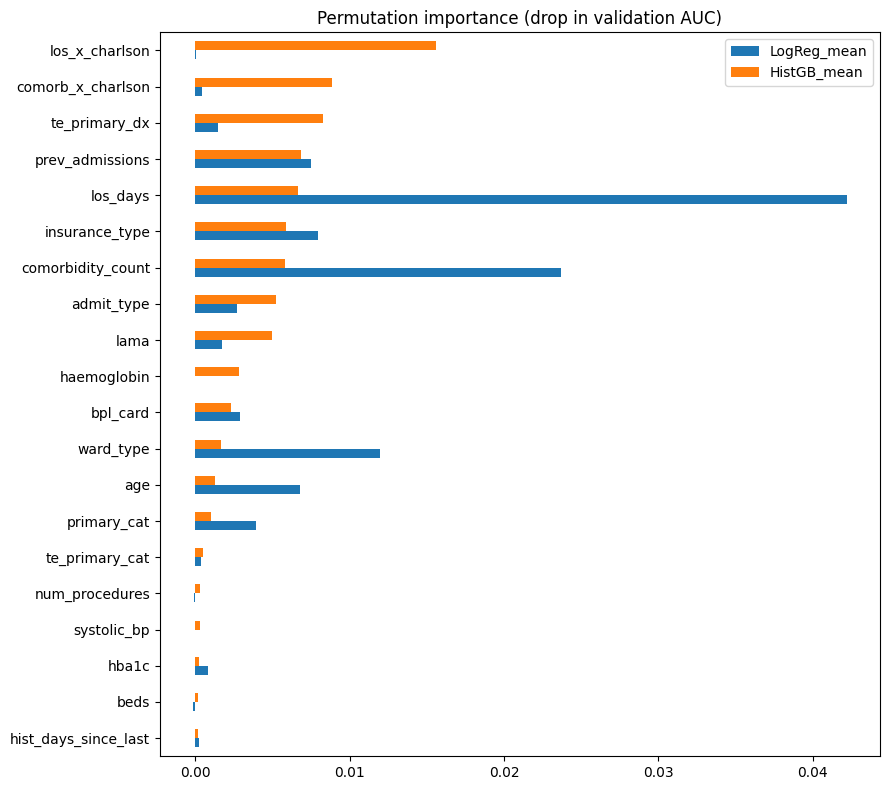

In [5]:
num_e, cat_e = SETS['engineered']; cols_e = num_e + cat_e
imps = {}
for name in ['LogReg', 'HistGB']:
    m = fit_model(name, num_e, cat_e)
    r = permutation_importance(m, X_all[cols_e].iloc[va], y[va], scoring='roc_auc', n_repeats=CFG['PERM_REPEATS'], random_state=0, n_jobs=1)
    imps[name] = pd.DataFrame({'mean': r.importances_mean, 'std': r.importances_std}, index=cols_e)
IMP = pd.concat(imps, axis=1); IMP.columns = [f'{a}_{b}' for a, b in IMP.columns]
useful = lambda m: (IMP[f'{m}_mean'] - 2 * IMP[f'{m}_std']) > 0
IMP['keep'] = useful('LogReg') | useful('HistGB')
IMP = IMP.sort_values('HistGB_mean', ascending=False); IMP.to_csv(os.path.join(OUT, 'feature_importance.csv'))
print(IMP.round(4).to_string())
kept = IMP.index[IMP.keep].tolist(); dropped = IMP.index[~IMP.keep].tolist()
print(f'\nKEEP {len(kept)}: {kept}\nDROP {len(dropped)}: {dropped}')
SETS['selected'] = ([c for c in num_e if c in kept], [c for c in cat_e if c in kept])
top = IMP.head(20)[['LogReg_mean', 'HistGB_mean']][::-1]; top.plot.barh(figsize=(9, 8), title='Permutation importance (drop in validation AUC)'); plt.tight_layout()
plt.savefig(os.path.join(OUT, 'importance.png'), dpi=150); plt.show()

## 5. Train every model on every feature set

baseline    LogReg       val AUC=0.7381  test AUC=0.7545  PR-AUC=0.3575
baseline    HistGB       val AUC=0.7385  test AUC=0.7530  PR-AUC=0.3515
baseline    RandomForest val AUC=0.7329  test AUC=0.7497  PR-AUC=0.3385
engineered  LogReg       val AUC=0.7390  test AUC=0.7555  PR-AUC=0.3596
engineered  HistGB       val AUC=0.7382  test AUC=0.7536  PR-AUC=0.3517
engineered  RandomForest val AUC=0.7338  test AUC=0.7507  PR-AUC=0.3423
selected    LogReg       val AUC=0.7397  test AUC=0.7554  PR-AUC=0.3590
selected    HistGB       val AUC=0.7393  test AUC=0.7533  PR-AUC=0.3536
selected    RandomForest val AUC=0.7331  test AUC=0.7499  PR-AUC=0.3430

   features        model  n_features  val_AUC  AUC_ROC  PR_AUC     F1  Precision  Recall  P@R60  Flagged%@R
  baseline       LogReg          26   0.7381   0.7545  0.3575 0.3855     0.3244  0.4750 0.2670     29.6808
  baseline       HistGB          26   0.7385   0.7530  0.3515 0.3819     0.3122  0.4917 0.2639     29.6095
  baseline RandomForest      

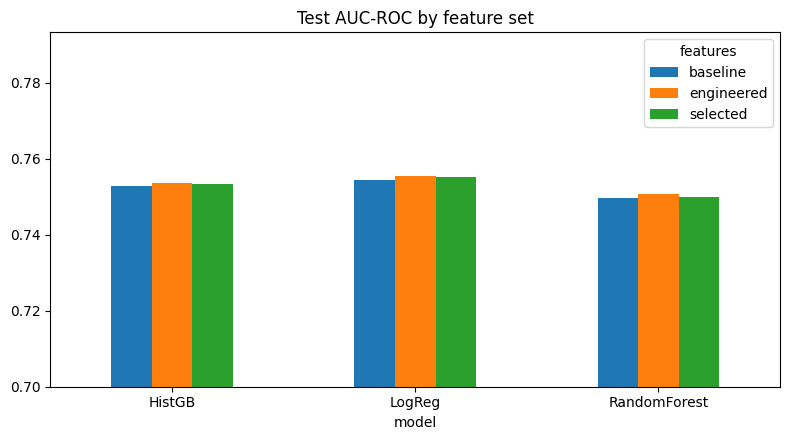

In [6]:
RES, PRED = [], {}
for sname, (num, cat) in SETS.items():
    for mname in ['LogReg', 'HistGB', 'RandomForest']:
        m = fit_model(mname, num, cat); X = X_all[num + cat]
        pv, pt = m.predict_proba(X.iloc[va])[:, 1], m.predict_proba(X.iloc[te])[:, 1]
        PRED[(sname, mname)] = (pv, pt); RES.append(dict(features=sname, model=mname, n_features=len(num + cat), val_AUC=roc_auc_score(y[va], pv), **evaluate(pv, pt)))
        print(f"{sname:11s} {mname:12s} val AUC={RES[-1]['val_AUC']:.4f}  test AUC={RES[-1]['AUC_ROC']:.4f}  PR-AUC={RES[-1]['PR_AUC']:.4f}")
R = pd.DataFrame(RES); R.to_csv(os.path.join(OUT, 'results.csv'), index=False)
print('\n', R.round(4).to_string(index=False))
R.pivot(index='model', columns='features', values='AUC_ROC')[list(SETS)].plot.bar(rot=0, title='Test AUC-ROC by feature set', figsize=(8, 4.5)); plt.ylim(0.7, None)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'auc_by_features.png'), dpi=150); plt.show()

## 6. Did the engineering really help? Paired patient-level bootstrap (best model by validation AUC)

In [7]:
best = R.sort_values('val_AUC', ascending=False).iloc[0]; bm, bf = best.model, best.features
print(f'Best by validation AUC: {bm} on {bf} features')
p_new, p_old = PRED[(bf, bm)][1], PRED[('baseline', bm)][1]
pid = pd.factorize(df.patient_id)[0][te]; groups = {p: np.where(pid == p)[0] for p in np.unique(pid)}; keys = np.array(list(groups)); rng = np.random.default_rng(1); ds = []
for _ in range(CFG['N_BOOT']):
    idx = np.concatenate([groups[k] for k in rng.choice(keys, len(keys))])
    if y[te][idx].min() == y[te][idx].max(): continue
    ds.append(roc_auc_score(y[te][idx], p_new[idx]) - roc_auc_score(y[te][idx], p_old[idx]))
print(f'AUC({bf}) - AUC(baseline) for {bm}: {np.mean(ds):+.4f}  95% CI [{np.percentile(ds, 2.5):+.4f}, {np.percentile(ds, 97.5):+.4f}]')
print('-> real improvement only if the whole interval is above 0.' if np.percentile(ds, 2.5) > 0 else '-> not distinguishable from zero; the baseline features were already enough.')

Best by validation AUC: LogReg on selected features
AUC(selected) - AUC(baseline) for LogReg: +0.0009  95% CI [-0.0001, +0.0018]
-> not distinguishable from zero; the baseline features were already enough.


## 7. Calibration and operating points for the best model

In [8]:
pv, pt = PRED[(bf, bm)]
iso = IsotonicRegression(out_of_bounds='clip').fit(pv, y[va]); pt_cal = iso.predict(pt)
print(f'Brier raw {brier_score_loss(y[te], pt):.4f} -> calibrated {brier_score_loss(y[te], pt_cal):.4f} (no-skill {brier_score_loss(y[te], np.full(len(te), prior)):.4f})')
rows = []
for q in [0.05, 0.10, 0.20, 0.30]:                      # flag the top q% highest-risk patients using the validation-set cut-off
    thr = np.quantile(pv, 1 - q); f = pt >= thr
    rows.append(dict(flag_top=f'{int(q*100)}%', precision=y[te][f].mean(), recall=y[te][f].sum() / y[te].sum(), lift=y[te][f].mean() / y[te].mean()))
print('\nIf the hospital reviews only the top-risk patients:\n', pd.DataFrame(rows).round(3).to_string(index=False))
pd.DataFrame({'admission_id': df.admission_id.values[te], 'y': y[te], 'p_raw': pt, 'p_calibrated': pt_cal}).to_csv(os.path.join(OUT, 'best_model_test_predictions.csv'), index=False)
print('saved to', OUT)

Brier raw 0.0959 -> calibrated 0.0963 (no-skill 0.1099)

If the hospital reviews only the top-risk patients:
 flag_top  precision  recall  lift
      5%      0.494   0.206 3.928
     10%      0.409   0.324 3.253
     20%      0.318   0.502 2.528
     30%      0.268   0.635 2.131
saved to fe_outputs
